# Heart Disease Prediction System

**Course:** AIC354 — Machine Learning Fundamentals  
**Assignment 2:** Developing an End-to-End Machine Learning System

**Deployment Link:** https://heart-disease-prediction-gcicdgv4pn7mfeub4syrmr.streamlit.app/

**Objective:** To develop a machine learning system that predicts whether heart disease is present using four selected attributes from the UCI Heart Disease dataset.

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("Libraries imported successfully.")

Libraries imported successfully.


In [5]:
columns = [
    "age", "sex", "cp", "trestbps", "chol", "fbs",
    "restecg", "thalach", "exang", "oldpeak",
    "slope", "ca", "thal", "num"
]

df = pd.read_csv(
    "processed.cleveland.data",
    header=None,
    names=columns,
    na_values="?"
)

print("Dataset loaded successfully.")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully.
Dataset shape: (303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


In [6]:
print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nFirst five records:")
display(df.head())

print("\nMissing values in each column:")
print(df.isnull().sum())

Column names:
['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'num']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    float64
 1   sex       303 non-null    float64
 2   cp        303 non-null    float64
 3   trestbps  303 non-null    float64
 4   chol      303 non-null    float64
 5   fbs       303 non-null    float64
 6   restecg   303 non-null    float64
 7   thalach   303 non-null    float64
 8   exang     303 non-null    float64
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    float64
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  num       303 non-null    int64  
dtypes: float64(13), int64(1)
memory usage: 33.3 KB

First five records:


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0



Missing values in each column:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
num         0
dtype: int64


In [7]:
# Convert dataset columns to numeric values
df = df.apply(pd.to_numeric, errors="coerce")

# Select the four required input attributes and target
selected_columns = ["age", "sex", "cp", "thalach", "num"]
data = df[selected_columns].copy()

# Remove rows with missing values in selected columns
data.dropna(inplace=True)

# Convert the original target into two classes
data["target_label"] = np.where(
    data["num"] == 0,
    "No Disease",
    "Disease Present"
)

# Encode target labels as numbers
label_encoder = LabelEncoder()
data["target"] = label_encoder.fit_transform(data["target_label"])

print("Target encoding:")
for label, encoded_value in zip(
    label_encoder.classes_,
    label_encoder.transform(label_encoder.classes_)
):
    print(f"{label}: {encoded_value}")

print("\nCleaned dataset shape:", data.shape)
display(data.head())

Target encoding:
Disease Present: 0
No Disease: 1

Cleaned dataset shape: (303, 7)


,age,sex,cp,thalach,num,target_label,target
0,63.0,1.0,1.0,150.0,0,No Disease,1
1,67.0,1.0,4.0,108.0,2,Disease Present,0
2,67.0,1.0,4.0,129.0,1,Disease Present,0
3,37.0,1.0,3.0,187.0,0,No Disease,1
4,41.0,0.0,2.0,172.0,0,No Disease,1


Target class distribution:
target_label
No Disease         164
Disease Present    139
Name: count, dtype: int64


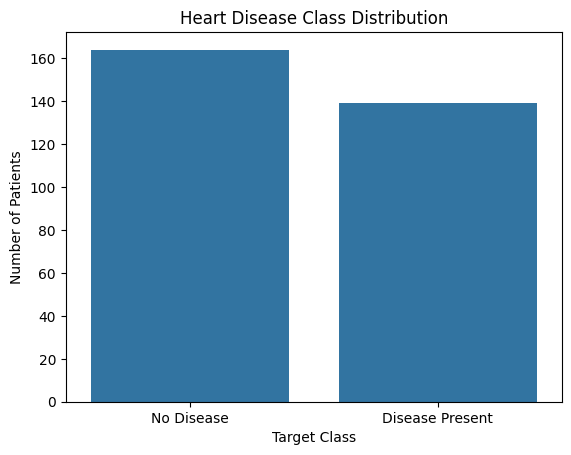

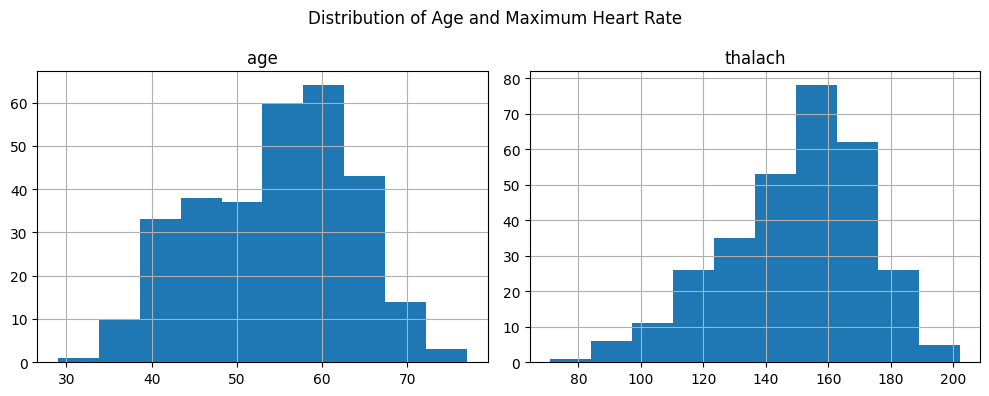

In [8]:
print("Target class distribution:")
print(data["target_label"].value_counts())

sns.countplot(data=data, x="target_label")
plt.title("Heart Disease Class Distribution")
plt.xlabel("Target Class")
plt.ylabel("Number of Patients")
plt.show()

data[["age", "thalach"]].hist(figsize=(10, 4))
plt.suptitle("Distribution of Age and Maximum Heart Rate")
plt.tight_layout()
plt.show()

In [9]:
feature_names = ["age", "sex", "cp", "thalach"]

X = data[feature_names]
y = data["target"]

print("Selected input attributes:", feature_names)
print("Number of input attributes:", len(feature_names))
print("Features shape:", X.shape)
print("Target shape:", y.shape)

Selected input attributes: ['age', 'sex', 'cp', 'thalach']
Number of input attributes: 4
Features shape: (303, 4)
Target shape: (303,)


In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 242
Testing records: 61


In [11]:
model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", SVC(kernel="rbf", random_state=42))
])

model.fit(X_train, y_train)

print("Model training completed successfully.")

Model training completed successfully.


In [12]:
y_pred = model.predict(X_test)

print("Model Evaluation")
print("----------------")

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, y_pred, zero_division=0), 4))
print("F1-score:", round(f1_score(y_test, y_pred, zero_division=0), 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=label_encoder.classes_,
    zero_division=0
))

Model Evaluation
----------------
Accuracy: 0.7869
Precision: 0.8333
Recall: 0.7576
F1-score: 0.7937

Classification Report:
                 precision    recall  f1-score   support

Disease Present       0.74      0.82      0.78        28
     No Disease       0.83      0.76      0.79        33

       accuracy                           0.79        61
      macro avg       0.79      0.79      0.79        61
   weighted avg       0.79      0.79      0.79        61



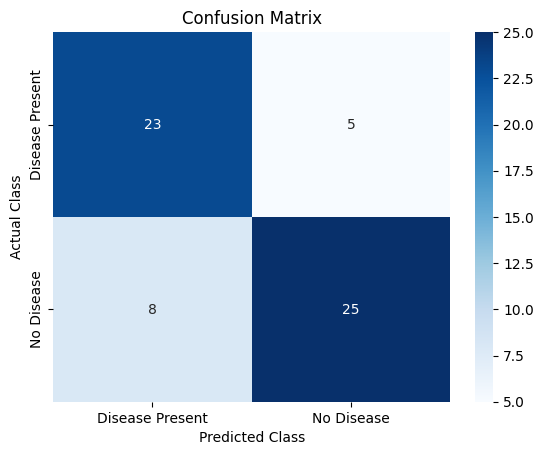

In [13]:
cm = confusion_matrix(y_test, y_pred)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.show()

In [14]:
joblib.dump(model, "heart_disease_model.pkl")

print("Trained model saved as heart_disease_model.pkl")

Trained model saved as heart_disease_model.pkl


In [15]:
# Example input: age, sex, chest pain type, maximum heart rate
sample_patient = pd.DataFrame(
    [[50, 1, 2, 150]],
    columns=feature_names
)

prediction = model.predict(sample_patient)[0]

predicted_label = label_encoder.inverse_transform([prediction])[0]

print("Sample patient attributes:")
display(sample_patient)

print("Model prediction:", predicted_label)
print("This is a demonstration prediction, not a medical diagnosis.")

Sample patient attributes:


,age,sex,cp,thalach
0,50,1,2,150


Model prediction: No Disease
This is a demonstration prediction, not a medical diagnosis.


## Conclusion

In this project, a Heart Disease Prediction System was developed using the UCI Heart Disease dataset. Four attributes—age, sex, chest pain type, and maximum heart rate—were selected as inputs. The data was prepared, divided into training and testing sets, and used to train a Support Vector Classifier.

The model was evaluated using accuracy, precision, recall, F1-score, and a confusion matrix. The trained model was also saved for use in a deployed application. This project demonstrates the main steps involved in developing an end-to-end machine learning system.

The model is intended for educational purposes and should not be used to make medical decisions.